In [1]:
# %%
import json
import math
from typing import Any, Dict, Iterable, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Rectangle, ConnectionPatch, Polygon

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)
plt.rcParams["figure.figsize"] = (10, 6)

# ---- file paths: update the match_id file names accordingly ----
MATCHES_CSV   = "matches_df.csv"
LINEUPS_CSV   = "lineups_df.csv"
EVENTS_CSV    = "events_by_match/events_3788741.csv"         # change to your chosen match file
FRAMES360_CSV = "frames_360_by_match/frames_360_3788741.csv"     # same match_id


In [2]:
# %%
matches = pd.read_csv(MATCHES_CSV)
lineups = pd.read_csv(LINEUPS_CSV)
events  = pd.read_csv(EVENTS_CSV)
frames  = pd.read_csv(FRAMES360_CSV)

print("matches:", matches.shape, "| lineups:", lineups.shape, "| events:", events.shape, "| frames:", frames.shape)
print("\nEvents head columns:", list(events.columns[:20]))
print("Frames head columns:", list(frames.columns))


matches: (51, 22) | lineups: (2345, 10) | events: (3803, 115) | frames: (45737, 7)

Events head columns: ['fifty_fifty', 'bad_behaviour_card', 'ball_receipt_outcome', 'ball_recovery_offensive', 'ball_recovery_recovery_failure', 'block_deflection', 'block_offensive', 'block_save_block', 'carry_end_location', 'clearance_aerial_won', 'clearance_body_part', 'clearance_head', 'clearance_left_foot', 'clearance_other', 'clearance_right_foot', 'counterpress', 'dribble_no_touch', 'dribble_nutmeg', 'dribble_outcome', 'dribble_overrun']
Frames head columns: ['id', 'match_id', 'visible_area', 'teammate', 'actor', 'keeper', 'location']


In [3]:
# %%
assert "match_id" in events.columns and "id" in events.columns, "events missing match_id or id"
assert "match_id" in frames.columns and "id" in frames.columns, "frames missing match_id or id"

# choose the match_id present in the event file (assume one match)
match_id = int(events["match_id"].mode().iloc[0])
mrow = matches.loc[matches["match_id"] == match_id]
print(f"Match row found? {not mrow.empty} | match_id={match_id}")

# helpful: infer side (home/away) from team name
def infer_side(team_name: str, home: str, away: str) -> Optional[str]:
    if pd.isna(team_name):
        return None
    if team_name == home:
        return "home"
    if team_name == away:
        return "away"
    return None

if not mrow.empty and {"home_team","away_team"}.issubset(mrow.columns):
    home, away = mrow.iloc[0]["home_team"], mrow.iloc[0]["away_team"]
    events["side"] = events["team"].apply(lambda t: infer_side(t, home, away))
else:
    events["side"] = None

# confirm coverage: fraction of events that have frames
has_frames = events["id"].isin(frames["id"]).mean()
print(f"Share of events with 360 freeze-frames: {has_frames:0.2%}")


Match row found? True | match_id=3788741
Share of events with 360 freeze-frames: 88.61%


In [4]:
# %%
def try_json(x):
    if pd.isna(x):
        return None
    if isinstance(x, (list, dict)):
        return x
    s = str(x)
    try:
        return json.loads(s)
    except Exception:
        # some CSVs store lists as like "[52.3, 33.2]"
        # or with single quotes — try a fallback
        try:
            return json.loads(s.replace("'", '"'))
        except Exception:
            return None

def parse_point(pt) -> Optional[Tuple[float,float]]:
    if isinstance(pt, (list, tuple)) and len(pt) >= 2:
        return float(pt[0]), float(pt[1])
    return None

def draw_pitch(ax=None, linecolor="black", lw=1):
    if ax is None:
        ax = plt.gca()
    ax.set_xlim(0, 120)
    ax.set_ylim(0, 80)
    ax.set_aspect("equal")
    ax.axis("off")
    # outline & halves
    ax.add_patch(Rectangle((0, 0), 120, 80, fill=False, ec=linecolor, lw=lw))
    ax.plot([60, 60], [0, 80], color=linecolor, lw=lw)
    # boxes
    ax.add_patch(Rectangle((0, 18), 18, 44, fill=False, ec=linecolor, lw=lw))      # left box
    ax.add_patch(Rectangle((102, 18), 18, 44, fill=False, ec=linecolor, lw=lw))     # right box
    # six-yard
    ax.add_patch(Rectangle((0, 30), 6, 20, fill=False, ec=linecolor, lw=lw))
    ax.add_patch(Rectangle((114, 30), 6, 20, fill=False, ec=linecolor, lw=lw))
    # penalty spots & arcs
    ax.plot(12, 40, 'o', color=linecolor, ms=2)
    ax.plot(108, 40, 'o', color=linecolor, ms=2)
    ax.add_patch(Arc((12, 40), 20, 20, angle=0, theta1=-90, theta2=90, ec=linecolor, lw=lw))
    ax.add_patch(Arc((108, 40), 20, 20, angle=0, theta1=90, theta2=270, ec=linecolor, lw=lw))
    # center circle
    ax.add_patch(Arc((60, 40), 20, 20, angle=0, theta1=0, theta2=360, ec=linecolor, lw=lw))
    return ax


In [5]:
# %%
shots = events[events["type"] == "Shot"].copy()
shots["xy"] = shots["location"].apply(try_json).apply(parse_point)
shots["end_xy"] = shots["shot_end_location"].apply(try_json).apply(parse_point) if "shot_end_location" in shots.columns else None

shots["x"] = shots["xy"].apply(lambda p: p[0] if p else np.nan)
shots["y"] = shots["xy"].apply(lambda p: p[1] if p else np.nan)
if "shot_statsbomb_xg" in shots.columns:
    shots["xg"] = pd.to_numeric(shots["shot_statsbomb_xg"], errors="coerce")
else:
    shots["xg"] = np.nan

summary = shots.groupby("team").agg(
    shots=("id","count"),
    goals=("shot_outcome", lambda s: (s=="Goal").sum() if s is not None else np.nan),
    xg=("xg","sum"),
    avg_xg=("xg","mean")
).sort_values("xg", ascending=False)
print("Shot / xG summary by team:\n", summary.fillna(0).round(3))

# # --- Plot: shot map colored by xG (one example: home team) ---
# home_team = mrow.iloc[0]["home_team"] if not mrow.empty else shots["team"].iloc[0]
# subset = shots[shots["team"] == home_team]

# fig, ax = plt.subplots()
# draw_pitch(ax)
# sc = ax.scatter(subset["x"], subset["y"], s=40 + 200*subset["xg"].fillna(0), alpha=0.7)
# ax.set_title(f"Shot Map — {home_team} (size ~ xG)")
# plt.show()

# # --- Plot: shot map colored by xG (one example: home team) ---
# away_team = mrow.iloc[0]["away_team"] if not mrow.empty else shots["team"].iloc[0]
# subset = shots[shots["team"] == away_team]

# fig, ax = plt.subplots()
# draw_pitch(ax)
# sc = ax.scatter(subset["x"], subset["y"], s=40 + 200*subset["xg"].fillna(0), alpha=0.7)
# ax.set_title(f"Shot Map — {away_team} (size ~ xG)")
# plt.show()

import plotly.graph_objects as go
import json

def make_pitch(fig):
    """Add soccer pitch lines to a Plotly figure."""
    # Outline
    fig.add_shape(type="rect", x0=0, y0=0, x1=120, y1=80, line=dict(color="black", width=1))
    # Halfway line
    fig.add_shape(type="line", x0=60, y0=0, x1=60, y1=80, line=dict(color="black", width=1))
    # Penalty boxes
    fig.add_shape(type="rect", x0=0, y0=18, x1=18, y1=62, line=dict(color="black", width=1))
    fig.add_shape(type="rect", x0=102, y0=18, x1=120, y1=62, line=dict(color="black", width=1))
    # 6-yard boxes
    fig.add_shape(type="rect", x0=0, y0=30, x1=6, y1=50, line=dict(color="black", width=1))
    fig.add_shape(type="rect", x0=114, y0=30, x1=120, y1=50, line=dict(color="black", width=1))
    # Penalty spots
    fig.add_trace(go.Scatter(x=[12, 108], y=[40, 40], mode="markers",
                             marker=dict(color="black", size=4), showlegend=False))
    # Center circle
    circle = dict(type="circle", xref="x", yref="y",
                  x0=60-10, y0=40-10, x1=60+10, y1=40+10,
                  line=dict(color="black", width=1))
    fig.add_shape(circle)
    return fig


def make_shotmap(team_name, shots_df):
    """Create a Plotly shot map for one team, with goals ringed in black."""
    subset = shots_df[shots_df["team"] == team_name].copy()

    # Identify goals
    is_goal = subset["shot_outcome"].fillna("").str.lower() == "goal"

    # Main scatter: all shots
    fig = go.Figure()

    # Plot all shots (including goals) with normal marker
    fig.add_trace(go.Scatter(
        x=subset["x"],
        y=subset["y"],
        mode="markers",
        marker=dict(
            size=10 + 60 * subset["xg"].fillna(0),
            color=subset["xg"],
            colorscale="Reds",
            cmin=0,
            cmax=subset["xg"].max(),
            showscale=True,
            colorbar=dict(title="xG"),
            line=dict(width=0)  # No border for non-goals
        ),
        text=[
            f"<b>{row['player']}</b><br>"
            f"Minute: {row['minute']}<br>"
            f"Second: {row['second']}<br>"
            f"xG: {row['xg']:.3f}<br>"
            f"Outcome: {row['shot_outcome']}"
            for _, row in subset.iterrows()
        ],
        hoverinfo="text",
        name="Shot"
    ))

    # Overlay: goals with black ring
    if is_goal.any():
        fig.add_trace(go.Scatter(
            x=subset.loc[is_goal, "x"],
            y=subset.loc[is_goal, "y"],
            mode="markers",
            marker=dict(
                size=10 + 60 * subset.loc[is_goal, "xg"].fillna(0),
                color=subset.loc[is_goal, "xg"],
                colorscale="Reds",
                cmin=0,
                cmax=subset["xg"].max(),
                showscale=False,
                line=dict(width=3, color="black")
            ),
            text=[
                f"<b>{row['player']}</b><br>"
                f"Minute: {row['minute']}<br>"
                f"Second: {row['second']}<br>"
                f"xG: {row['xg']:.3f}<br>"
                f"Outcome: {row['shot_outcome']}"
                for _, row in subset[is_goal].iterrows()
            ],
            hoverinfo="text",
            name="Goal"
        ))

    # Add pitch lines
    fig = make_pitch(fig)

    # Layout
    fig.update_layout(
        title=f"Shot Map — {team_name} (size ~ xG)",
        xaxis=dict(showgrid=False, visible=False, range=[0, 120]),
        yaxis=dict(showgrid=False, visible=False, range=[0, 80]),
        plot_bgcolor="white",
        height=600,
        width=900
    )

    fig.update_yaxes(autorange="reversed")  # match pitch orientation

    return fig


# --- Create and save both plots ---
home_team = mrow.iloc[0]["home_team"] if not mrow.empty else shots["team"].iloc[0]
away_team = mrow.iloc[0]["away_team"] if not mrow.empty else shots["team"].iloc[1]

fig_home = make_shotmap(home_team, shots)
fig_away = make_shotmap(away_team, shots)

# Show both inline for testing
fig_home.show()
fig_away.show()

fig_home.write_json(f"viz/match_{match_id}_{home_team}_shotmap.json")
fig_away.write_json(f"viz/match_{match_id}_{away_team}_shotmap.json")



#making sure they reload

# import json, plotly.io as pio

# for team in [home_team, away_team]:
#     path = f"viz/match_1_{team}_shotmap.json"
#     with open(path) as f:
#         fig_dict = json.load(f)
#     pio.from_json(json.dumps(fig_dict)).show()



Shot / xG summary by team:
         shots  goals     xg  avg_xg
team                               
Italy      24      2  1.591   0.066
Turkey      3      0  0.151   0.050


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/kaleido/__init__.py:14: UserWarning:




This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.




In [47]:
# Find all shots with xG >= 0.08
shots_high_xg = shots[shots["xg"] >= 0.08].copy()

# Get unique possession numbers for these shots
high_xg_possessions = shots_high_xg["possession"].unique()

# For each possession, retrieve all events in the possession leading up to the shot
possessions_events = {}
for pos_num in high_xg_possessions:
    # All events with this possession number, ordered by event index/id if available
    # (Assumption: "index" or "event_id" or row index gives chronological order, else fallback to DataFrame order)
    possession_events = events[events["possession"] == pos_num]
    # Optional: sort if you have a 'minute', 'second', or 'index' column
    if "index" in possession_events.columns:
        possession_events = possession_events.sort_values("index")
    elif "event_id" in possession_events.columns:
        possession_events = possession_events.sort_values("event_id")
    possessions_events[pos_num] = possession_events

# # Optionally: print summaries for each possession
# for pos_num, evdf in possessions_events.items():
#     print(f"\n--- Possession {pos_num} ---")
#     print(evdf[["minute", "second", "team", "type", "player", "x", "y", "outcome", "xg"]]
#           if all(c in evdf.columns for c in ["minute", "second", "team", "type", "player", "x", "y", "outcome", "xg"])
#           else evdf.head(10))

In [48]:
len(high_xg_possessions)

6

In [73]:
# Only look at events for a single possession at a time
# Pick a possession number to examine (choose from one in 'high_xg_possessions', e.g., high_xg_possessions[0])
single_possession_num = high_xg_possessions[2]  # Or change to any possession number you are interested in

df = possessions_events[single_possession_num]

# Reorder columns for easier reading
cols_first = [
    "type", "minute", "timestamp", "second", "location", "play_pattern", "player", "position", "shot_statsbomb_xg",
    "possession", "possession_team", "pass_angle", "pass_end_location", "pass_height", "pass_length",
    "pass_recipient", "pass_technique", "team", "period", 
]
# Remove duplicates if present
cols_first = [c for i, c in enumerate(cols_first) if c not in cols_first[:i]]

def reorder_cols(df, cols_first):
    all_cols = df.columns.tolist()
    first = [c for c in cols_first if c in all_cols]
    rest = [c for c in all_cols if c not in first]
    return df[first + rest]

reordered_df = reorder_cols(df, cols_first)
# Add a "source_possession" column for clarity (optional)
reordered_df = reordered_df.copy()
reordered_df["source_possession"] = single_possession_num

reordered_df = reordered_df.sort_values("timestamp")

In [74]:
# Find the 'Shot' event in reordered_df
shot_row = reordered_df[(reordered_df['type'] == 'Shot') & (reordered_df['shot_statsbomb_xg'] >= 0.08)]
if not shot_row.empty:
    # Get the minute and second of the shot event (take first if multiple)
    shot_minute = shot_row.iloc[0]['minute']
    shot_second = shot_row.iloc[0]['second']
    # Convert to absolute time in seconds
    shot_abs_time = shot_minute * 60 + shot_second
    # Add absolute time to the dataframe for filtering
    reordered_df = reordered_df.copy()
    reordered_df['abs_time'] = reordered_df['minute'] * 60 + reordered_df['second']
    # Take only events in the 10 seconds preceding (inclusive of the 'Shot' event)
    reordered_df_special = reordered_df[
        (reordered_df['abs_time'] >= shot_abs_time - 10) &
        (reordered_df['abs_time'] <= shot_abs_time)
    ]
    # Optionally, drop the helper column
    reordered_df_special = reordered_df_special.drop(columns=['abs_time'])
else:
    # If no Shot, just return empty or all
    reordered_df_special = reordered_df.iloc[0:0]
reordered_df_special

reordered_df_special['type'].value_counts()

type
Carry            3
Ball Receipt*    3
Pressure         3
Pass             2
Interception     1
Shot             1
Block            1
Goal Keeper      1
Name: count, dtype: int64

In [85]:
reordered_df_special

,type,minute,timestamp,second,location,play_pattern,player,position,shot_statsbomb_xg,possession,possession_team,pass_angle,pass_end_location,pass_height,pass_length,pass_recipient,pass_technique,team,period,fifty_fifty,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,block_save_block,carry_end_location,clearance_aerial_won,clearance_body_part,clearance_head,clearance_left_foot,clearance_other,clearance_right_foot,counterpress,dribble_no_touch,dribble_nutmeg,dribble_outcome,dribble_overrun,duel_outcome,duel_type,duration,foul_committed_advantage,foul_committed_card,foul_committed_offensive,foul_committed_penalty,foul_committed_type,foul_won_advantage,foul_won_defensive,foul_won_penalty,goalkeeper_body_part,goalkeeper_end_location,goalkeeper_lost_in_play,goalkeeper_outcome,goalkeeper_penalty_saved_to_post,goalkeeper_position,goalkeeper_punched_out,goalkeeper_shot_saved_off_target,goalkeeper_shot_saved_to_post,goalkeeper_success_in_play,goalkeeper_technique,goalkeeper_type,id,index_num,injury_stoppage_in_chain,interception_outcome,match_id,miscontrol_aerial_won,off_camera,out_play,pass_aerial_won,pass_assisted_shot_id,pass_body_part,pass_cross,pass_cut_back,pass_deflected,pass_goal_assist,pass_inswinging,pass_miscommunication,pass_no_touch,pass_outcome,pass_outswinging,pass_recipient_id,pass_shot_assist,pass_straight,pass_switch,pass_through_ball,pass_type,player_id,player_off_permanent,possession_team_id,related_events,shot_aerial_won,shot_body_part,shot_deflected,shot_end_location,shot_first_time,shot_follows_dribble,shot_freeze_frame,shot_key_pass_id,shot_one_on_one,shot_open_goal,shot_outcome,shot_redirect,shot_saved_off_target,shot_saved_to_post,shot_technique,shot_type,substitution_outcome,substitution_outcome_id,substitution_replacement,substitution_replacement_id,tactics,team_id,under_pressure,side,source_possession
2626,Carry,56,00:11:11.687,11,"[52.7, 45.5]",From Throw In,Ozan Tufan,Left Center Midfield,NaN,133,Italy,NaN,NaN,NaN,NaN,NaN,NaN,Turkey,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[52.2, 40.0]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.198217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ca2b9d00-c84f-4baa-a352-77d8aa1122d6,2405,NaN,NaN,3788741,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11088.0,NaN,914,"[""186c90d6-8cfc-4023-afc6-b0d89156b0a9"", ""80eb...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,909,1.0,home,133
1718,Ball Receipt*,56,00:11:11.687,11,"[52.7, 45.5]",From Throw In,Ozan Tufan,Left Center Midfield,NaN,133,Italy,NaN,NaN,NaN,NaN,NaN,NaN,Turkey,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,b22fb40c-34c6-479c-b683-93d31decfa2d,2404,NaN,NaN,3788741,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11088.0,NaN,914,"[""05075286-1cb6-4bf2-b4ff-4c3e1f03a962""]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,909,NaN,home,133
3191,Pressure,56,00:11:12.113,12,"[63.9, 33.2]",From Throw In,Jorge Luiz Frello Filho,Center Defensive Midfield,NaN,133,Italy,NaN,NaN,NaN,NaN,NaN,NaN,Italy,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,1.828265,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80eb2427-74bc-434a-b64b-c1d199003a9e,2406,NaN,NaN,3788741,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7024.0,NaN,914,"[""186c90d6-8cfc-4023-afc6-b0d89156b0a9"", ""ca2b...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,914,NaN,away,133
682,Pass,56,00:11:13.886,13,"[52.2, 40.0]",From Throw In,Ozan Tufan,Left Center Midfield,NaN,133,Italy,2.669815,"[32.6, 50.0]",Low Pass,22.003635,Merih Demir

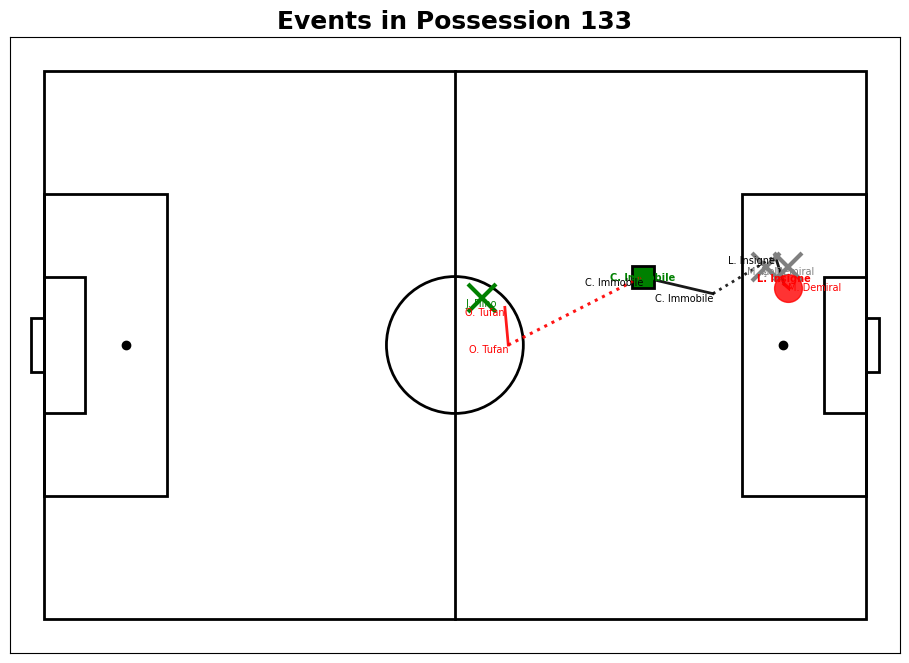

In [102]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_pitch(ax=None, color='black', lw=2):
    # Create a pitch 120 x 80 (standard StatsBomb coords)
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 8))
    # Outline & center line
    ax.add_patch(patches.Rectangle((0, 0), 120, 80, fill=False, edgecolor=color, lw=lw))
    ax.plot([60, 60], [0, 80], color=color, lw=lw)
    # Left penalty box
    ax.add_patch(patches.Rectangle((0, 18), 18, 44, fill=False, edgecolor=color, lw=lw))
    # Right penalty box
    ax.add_patch(patches.Rectangle((102, 18), 18, 44, fill=False, edgecolor=color, lw=lw))
    # Left 6-yard box
    ax.add_patch(patches.Rectangle((0, 30), 6, 20, fill=False, edgecolor=color, lw=lw))
    # Right 6-yard box
    ax.add_patch(patches.Rectangle((114, 30), 6, 20, fill=False, edgecolor=color, lw=lw))
    # Center circle
    cc = plt.Circle((60, 40), 10, color=color, fill=False, lw=lw)
    ax.add_patch(cc)
    # Penalty spots
    ax.plot(12, 80-40, marker='o', color=color)
    ax.plot(108, 80-40, marker='o', color=color)
    # Goals
    ax.add_patch(patches.Rectangle((-2, 80-36-8), 2, 8, fill=False, edgecolor=color, lw=lw))
    ax.add_patch(patches.Rectangle((120, 80-36-8), 2, 8, fill=False, edgecolor=color, lw=lw))
    ax.set_xlim(-5, 125)
    ax.set_ylim(-5, 85)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect('equal')
    return ax

def get_xy(loc_field):
    """Handle if location is a list or string, otherwise returns (nan, nan)."""
    import numpy as np
    if isinstance(loc_field, (list, tuple)) and len(loc_field) >= 2:
        return float(loc_field[0]), float(loc_field[1])
    elif isinstance(loc_field, str):
        try:
            arr = eval(loc_field)
            if isinstance(arr, (list, tuple)) and len(arr) >= 2:
                return float(arr[0]), float(arr[1])
        except:
            pass
    return (np.nan, np.nan)

def flip_y(y):
    if y is None:
        return None
    import numpy as np
    if np.isnan(y):
        return y
    return 80 - y

def flip_x(x):
    if x is None:
        return None
    import numpy as np
    if np.isnan(x):
        return x
    return 120 - x

def team_is_shot_team(event_row, shot_team):
    return (event_row.get('team', None) == shot_team)

def plot_squiggly(ax, x1, y1, x2, y2, color='gray', lw=2, zorder=3):
    import numpy as np
    t = np.linspace(0, 1, 100)
    dx = x2 - x1
    dy = y2 - y1
    length = np.sqrt(dx*dx + dy*dy)
    if length < 1e-2:
        return
    ortho_x = -dy / length
    ortho_y = dx / length
    A = min(2, 0.12 * length)
    freq = 10
    squiggle = A * np.sin(2 * np.pi * freq * t)
    x = x1 + dx * t + squiggle * ortho_x
    y = y1 + dy * t + squiggle * ortho_y
    ax.plot(x, y, color=color, linewidth=lw, alpha=0.75, zorder=zorder)

def format_player_name(full_name):
    """Format as 'F. Last' given a string like 'Firstname Lastname'."""
    if not isinstance(full_name, str) or len(full_name.strip()) == 0:
        return ""
    parts = full_name.split()
    if len(parts) == 1:
        return parts[0]
    first = parts[0]
    last = parts[-1]
    return f"{first[0]}. {last}"

# Get team of shot event (for conditional coloring)
shot_team = None
shot_row = reordered_df_special[reordered_df_special['type'] == 'Shot']
if not shot_row.empty and ('team' in shot_row.columns):
    shot_team = shot_row.iloc[0]['team']

ax = draw_pitch()
import numpy as np

for i, event in reordered_df_special.iterrows():
    typ = event.get('type', None)
    if pd.isna(typ): continue
    player = event.get('player', None)
    player_short = format_player_name(player)

    ###### Passes done by the opposition (not the shot team) #######
    if typ == "Pass" and not team_is_shot_team(event, shot_team):
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('pass_end_location'))

        # Flip BOTH start and end X and Y for opposition passes
        start_x_flipped = flip_x(start_x)
        end_x_flipped = flip_x(end_x)
        start_y_flipped = flip_y(start_y)
        end_y_flipped = end_y # unchanged as before

        if not (np.isnan(start_x_flipped) or np.isnan(end_x_flipped)):
            # Red dotted line for passes by the opposition
            ax.plot([start_x_flipped, end_x_flipped], [start_y_flipped, end_y_flipped],
                    color='red', linestyle=':', lw=2.2, alpha=0.92, zorder=13)
            # Annotate at start location
            if player_short:
                ax.text(start_x_flipped, start_y_flipped, player_short, fontsize=7,
                        color='red', verticalalignment='top', horizontalalignment='right', zorder=40)
        continue

    # Passes by shot team (keep as before: black dotted line, flip_y on Y only)
    if typ == "Pass":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('pass_end_location'))
        start_y_flipped = flip_y(start_y)
        end_y_flipped = flip_y(end_y)
        if not (np.isnan(start_x) or np.isnan(end_x)):
            ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='black', linestyle=':', lw=2, alpha=0.85, zorder=2)
            if player_short:
                ax.text(start_x, start_y_flipped, player_short, fontsize=7, color='black', verticalalignment='top', horizontalalignment='right', zorder=40)
        continue

    ###### Carry: black solid line for shot team, red solid line for opposition ######
    if typ == "Carry":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('carry_end_location'))

        if team_is_shot_team(event, shot_team):
            # By shot team: flip y, black line
            start_y_flipped = flip_y(start_y)
            end_y_flipped = flip_y(end_y)
            if not (np.isnan(start_x) or np.isnan(end_x)):
                ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='black', linestyle='-', lw=2, alpha=0.9, zorder=3)
                if player_short:
                    ax.text(start_x, start_y_flipped, player_short, fontsize=7, color='black', verticalalignment='top', horizontalalignment='right', zorder=40)
        else:
            # By opposition: NO flip, red line
            # Flip BOTH start and end X for opposition carries, don't flip Y at all
            start_x_flipped = flip_x(start_x)
            end_x_flipped = flip_x(end_x)
            if not (np.isnan(start_x_flipped) or np.isnan(end_x_flipped)):
                ax.plot([start_x_flipped, end_x_flipped], [start_y, end_y], color='red', linestyle='-', lw=2, alpha=0.9, zorder=3)
                if player_short:
                    ax.text(start_x_flipped, start_y, player_short, fontsize=7, color='red', verticalalignment='top', horizontalalignment='right', zorder=40)
        continue

    ###### Dribble - small squiggly gray line ######
    if typ == "Dribble":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('dribble_end_location'))
        start_y_flipped = flip_y(start_y)
        end_y_flipped = flip_y(end_y)
        if (not np.isnan(start_x)) and (not np.isnan(end_x)):
            plot_squiggly(ax, start_x, start_y_flipped, end_x, end_y_flipped, color='gray', lw=2, zorder=4)
            if player_short:
                ax.text(start_x, start_y_flipped, player_short, fontsize=7, color='gray', verticalalignment='top', horizontalalignment='left', zorder=40)
        continue

    ###### Dribbled Past - small red X ######
    if typ == "Dribbled Past":
        x, y = get_xy(event.get('location'))
        y_flipped = flip_y(y)
        if not np.isnan(x):
            ax.plot(x, y_flipped, marker='x', color='red', markersize=13, markeredgewidth=2.8, zorder=9)
            if player_short:
                ax.text(x, y_flipped, player_short, fontsize=7, color='red', verticalalignment='bottom', horizontalalignment='left', zorder=40)
        continue

    ###### Blocks by the opposition (not shot team) -- red dot, flip Y only; flip both X and Y of text ######
    if typ == "Block" and not team_is_shot_team(event, shot_team):
        x, y = get_xy(event.get('location'))
        # x stays the same, y is flipped for marker
        x_flipped = flip_x(x)
        y_flipped = y#flip_y(y)
        if not np.isnan(x_flipped):
            ax.plot(x_flipped, y_flipped, marker='o', color='red', markersize=20, alpha=0.8, zorder=8)
            if player_short:
                x_text = flip_x(x)
                y_text = y#flip_y(y)
                ax.text(x_text, y_text, player_short, fontsize=7, color='red',
                        verticalalignment='center', horizontalalignment='left', zorder=40)
        continue

    ###### Blocks by shot team (same team as shot) -- red dot, flip X and Y ######
    if typ == "Block" and team_is_shot_team(event, shot_team):
        x, y = get_xy(event.get('location'))
        x_flipped = flip_x(x)
        y_flipped = flip_y(y)
        if not np.isnan(x_flipped):
            ax.plot(x_flipped, y_flipped, marker='o', color='red', markersize=20, alpha=0.8, zorder=8)
            if player_short:
                ax.text(x_flipped, y_flipped, player_short, fontsize=7, color='red', verticalalignment='center', horizontalalignment='left', zorder=40)
        continue

    ###### Ball Recovery: colored dot by team (shot team: green, else red) ######
    if typ == "Ball Recovery":
        x, y = get_xy(event.get('location'))
        y_flipped = flip_y(y)
        if not np.isnan(x):
            if team_is_shot_team(event, shot_team):
                ax.plot(x, y_flipped, marker='o', color='green', markersize=15, markeredgewidth=2, markeredgecolor='black', zorder=6)
                txt_color = 'green'
            else:
                ax.plot(x, y_flipped, marker='o', color='red', markersize=15, markeredgewidth=2, markeredgecolor='black', zorder=6)
                txt_color = 'red'
            if player_short:
                ax.text(x, y_flipped, player_short, fontsize=7, color=txt_color, verticalalignment='center', horizontalalignment='center', zorder=40, fontweight='semibold')
        continue

    ###### Pressure: X, green if shot team, gray if other. For opposition, flip Y for marker and for text ######
    if typ == "Pressure":
        x, y = get_xy(event.get('location'))
        if team_is_shot_team(event, shot_team):
            y_flipped = flip_y(y)
            if not np.isnan(x):
                ax.plot(x, y_flipped, marker='x', color='green', markersize=20, markeredgewidth=3, zorder=6)
                txt_color = 'green'
                if player_short:
                    ax.text(x, y_flipped, player_short, fontsize=7, color='green', verticalalignment='top', horizontalalignment='center', zorder=40)
        else:
            y_flipped = flip_y(y)
            x_flipped = flip_x(x)
            if not np.isnan(x_flipped):
                ax.plot(x_flipped, y, marker='x', color='gray', markersize=20, markeredgewidth=3, zorder=6)
                txt_color = 'gray'
                if player_short:
                    # flip the Y of the text for opposition
                    ax.text(x_flipped, y, player_short, fontsize=7, color='gray',
                            verticalalignment='top', horizontalalignment='center', zorder=40)
        continue

    ###### Clearance: by shot team = green dotted line, else red dotted line ######
    if typ == "Clearance":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('clearance_end_location'))
        start_y_flipped = flip_y(start_y)
        end_y_flipped = flip_y(end_y)
        if not (np.isnan(start_x) or np.isnan(end_x)):
            if team_is_shot_team(event, shot_team):
                ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='green', linestyle=':', lw=2.3, alpha=0.96, zorder=7)
                txt_color = 'green'
            else:
                ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='red', linestyle=':', lw=2.3, alpha=0.96, zorder=7)
                txt_color = 'red'
            if player_short:
                ax.text(start_x, start_y_flipped, player_short, fontsize=7, color=txt_color, verticalalignment='bottom', horizontalalignment='right', zorder=40)
        continue

    ###### Shot: red line from location to shot_end_location ######
    if typ == "Shot":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('shot_end_location'))
        start_y_flipped = flip_y(start_y)
        end_y_flipped = flip_y(end_y)
        if not (np.isnan(start_x) or np.isnan(end_x)):
            ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='red', linestyle='-', lw=2.5, alpha=0.95, zorder=10)
            if player_short:
                ax.text(start_x, start_y_flipped, player_short, fontsize=7, color='red', verticalalignment='bottom', horizontalalignment='center', zorder=40, fontweight='bold')
        continue

    ###### Interception: colored square by team (shot team: green, else red) ######
    if typ == "Interception":
        x, y = get_xy(event.get('location'))
        y_flipped = flip_y(y)
        if not np.isnan(x):
            color = 'green' if team_is_shot_team(event, shot_team) else 'red'
            ax.plot(x, y_flipped, marker='s', color=color, markersize=16, markeredgecolor='black', markeredgewidth=2, zorder=7)
            if player_short:
                ax.text(x, y_flipped, player_short, fontsize=7, color=color, verticalalignment='center', horizontalalignment='center', zorder=40, fontweight='bold' if color=='green' else 'normal')
        continue

    ###### Ball Receipt*: do nothing ######
    if typ == "Ball Receipt*":
        continue

ax.set_title(f"Events in Possession {single_possession_num}", fontsize=18, fontweight='bold')
plt.show()


In [ ]:
#separate thing - this is more towards match story, how things happen


    #chance #3: CAN WE ADD A HIGH TURNOVER FLAG SOMEHOW 

        #THE FACT THAT A PLAYER ON THE TEAM OPPOSITE THE SHOT MADE A PASS/DRIBBLE THAT failed, within their own half  

   
